<a href="https://www.kaggle.com/code/avikdas567/kinematic-threat-fusion-heterogeneous-boosting?scriptVersionId=364399742" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Latent Threat Vector Identification in Non-Stationary Transaction Streams via Kinematic Information Geometry and Heterogeneous Boosting

## Non-Parametric Rank Statistic Maximization and Variance-Reduced Ensembling under Extreme Class Asymmetry

---

# 1. Mathematical Problem Formulation & Inductive Learning Paradigm

Credit card transaction processing networks represent complex, non-stationary temporal systems operating under extreme class asymmetry. Let the transaction observation space be defined over a probability space $(\Omega, \mathcal{F}, \mathbb{P})$, with sample observations:

$$\mathcal{D} = \left\{ (\mathbf{x}_i, y_i) \right\}_{i=1}^N, \quad \mathbf{x}_i \in \mathcal{X} \subseteq \mathbb{R}^d, \quad y_i \in \{0, 1\}$$

where $\mathbf{x}_i$ denotes a mixed-type feature vector comprising continuous kinematic proxies, discrete temporal cycles, high-cardinality categorical metadata, and binary cyber-threat indicators. The target variable $y_i$ encodes transaction validity, where $y_i = 1$ designates a fraudulent event, and $y_i = 0$ designates a legitimate transaction.

The operational challenge is characterized by severe class imbalance, with empirical fraud incidence:

$$\pi = \mathbb{P}(Y = 1) \approx 0.0167 \quad (\approx 1.67\%)$$

Consequently, naive empirical risk minimization under standard 0-1 loss degrades into the majority-class trivial solution.

## 1.1 Invariant Rank Evaluation: Area Under the Receiver Operating Characteristic Curve (ROC-AUC)

Model performance in this competition is strictly benchmarked using the Area Under the Receiver Operating Characteristic Curve (ROC-AUC) between continuous predicted probabilities $\hat{p}_i = \hat{f}(\mathbf{x}_i) \in [0, 1]$ and true binary indicators $y_i$:

$$\mathcal{A} = \int_{0}^{1} \text{TPR}\left( \text{FPR}^{-1}(u) \right) du = \mathbb{P}\left(\hat{f}(X^+) > \hat{f}(X^-)\right)$$

where $X^+ \sim \mathbb{P}(\mathbf{X} \mid Y = 1)$ and $X^- \sim \mathbb{P}(\mathbf{X} \mid Y = 0)$. The empirical non-parametric Mann-Whitney $U$-statistic serves as the unbiased estimator:

$$\widehat{\mathcal{A}} = \frac{1}{N^+ N^-} \sum_{i \in \mathcal{S}^+} \sum_{j \in \mathcal{S}^-} \left[ \mathbb{I}\left(\hat{f}(\mathbf{x}_i) > \hat{f}(\mathbf{x}_j)\right) + \frac{1}{2}\mathbb{I}\left(\hat{f}(\mathbf{x}_i) = \hat{f}(\mathbf{x}_j)\right) \right]$$

where $\mathcal{S}^+ = \{i : y_i = 1\}$, $\mathcal{S}^- = \{j : y_j = 0\}$, $N^+ = |\mathcal{S}^+|$, and $N^- = |\mathcal{S}^-|$.

Because ROC-AUC is invariant under all strictly monotonically increasing continuous transformations $g: \mathbb{R} \to \mathbb{R}$:

$$\mathcal{A}(g \circ \hat{f}) \equiv \mathcal{A}(\hat{f})$$

the core inductive requirement is the preservation of global pairwise ordering rather than boundary threshold calibration. Nonetheless, combining probability-calibrated representations from distinct hypothesis classes minimizes predictive variance across the manifold.

## 1.2 End-to-End Architectural Architecture

This research presents a unified, multi-stage competitive pipeline:
1. **Computational Rigor & Determinism:** Full hardware and software seed locking across Python, NumPy, PyTorch, and gradient boosting runtimes, executed with warning suppression on dual NVIDIA T4 GPU infrastructure.
2. **Kinematic and Information-Theoretic Feature Engineering:** Physics-informed kinetic energy analogies, spatial displacement velocities, transaction flux densities, liquidity exhaustion metrics, and composite cyber-threat vector calculus.
3. **Leakage-Free 5-Fold Stratified Validation:** Exact target-proportional partitioning ensuring robust out-of-fold generalization without data contamination.
4. **Heterogeneous Model Families:**
   - **LightGBM:** Fast leaf-wise histogram gradient boosting with gradient-based one-side sampling.
   - **XGBoost:** Depth-wise exact second-order Taylor expansion tree boosting with histogram binning and L1/L2 regularization.
   - **CatBoost:** Oblivious decision trees with ordered target statistics to mitigate prediction shift on categorical interactions.
   - **Deep Tabular ResNet:** PyTorch neural architecture with learned entity embeddings, dense residual skip connections, batch normalization, and Swish activations.
5. **Meta-Optimization & Rank-Averaged Blending:** Direct ROC-AUC maximization using constrained Sequential Least Squares Programming (SLSQP) in rank and logit projection spaces.

# 2. Environment Configuration, Hardware Harness & Seed Locking

To ensure exact numerical reproducibility across repeated executions, seeds are anchored across Python hashing, NumPy random engines, and the PyTorch CUDA runtime. Deterministic cuDNN algorithms are enforced, and redundant library deprecation warnings are suppressed.

In [1]:
import os
import gc
import sys
import math
import time
import random
import logging
import warnings

# Suppress all system, future, and runtime warnings
warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import scipy as sp
from scipy import stats
from scipy.stats import rankdata
from scipy.optimize import minimize

import sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.preprocessing import RobustScaler

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import lightgbm as lgb
import xgboost as xgb

try:
    import catboost as cb
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "catboost", "-q"], check=True)
    import catboost as cb

# Set global reproducibility seeds
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)

# Multi-GPU Hardware Configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
gpu_count = torch.cuda.device_count() if torch.cuda.is_available() else 0

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Dataset directory paths
kaggle_path = "/kaggle/input/competitions/playground-series-s6e11"
local_path = "playground-series-s6e11"
dataset_dir = kaggle_path if os.path.exists(kaggle_path) else local_path

print(f"Computational Environment:")
print(f"  PyTorch Target Device: {device} (Detected GPUs: {gpu_count})")
print(f"  LightGBM Version: {lgb.__version__}")
print(f"  XGBoost Version: {xgb.__version__}")
print(f"  CatBoost Version: {cb.__version__}")
print(f"  Dataset Source Directory: {dataset_dir}")


Computational Environment:
  PyTorch Target Device: cuda (Detected GPUs: 2)
  LightGBM Version: 4.6.0
  XGBoost Version: 3.4.1
  CatBoost Version: 1.2.10
  Dataset Source Directory: /kaggle/input/competitions/playground-series-s6e11


# 3. Data Ingestion, Schema Auditing & Memory Optimization

The datasets are ingested from the specified environment directory. To maximize cache efficiency and prevent memory bottlenecks across large array manipulations, continuous variables are downcast from `float64` to `float32`, integers are downcast from `int64` to `int32`, and boolean threat vectors are represented as unsigned 8-bit integers.

In [2]:
def optimize_memory_footprint(df, verbose=True):
    start_mem = df.memory_usage().sum() / 1024**2
    for col in df.columns:
        col_type = df[col].dtype
        if col_type != object and col_type != 'category':
            c_min = df[col].min()
            c_max = df[col].max()
            if str(col_type).startswith('int'):
                if c_min >= -128 and c_max <= 127:
                    df[col] = df[col].astype(np.int8)
                elif c_min >= -32768 and c_max <= 32767:
                    df[col] = df[col].astype(np.int16)
                elif c_min >= -2147483648 and c_max <= 2147483647:
                    df[col] = df[col].astype(np.int32)
            elif str(col_type).startswith('float'):
                df[col] = df[col].astype(np.float32)
            elif str(col_type) == 'bool':
                df[col] = df[col].astype(np.uint8)
    end_mem = df.memory_usage().sum() / 1024**2
    if verbose:
        reduction = 100 * (start_mem - end_mem) / start_mem
        print(f"Memory reduction: {start_mem:.2f} MB -> {end_mem:.2f} MB ({reduction:.1f}% reduction)")
    return df

# Load datasets
train_df = pd.read_csv(os.path.join(dataset_dir, "train.csv"))
test_df = pd.read_csv(os.path.join(dataset_dir, "test.csv"))
sub_df = pd.read_csv(os.path.join(dataset_dir, "sample_submission.csv"))

print(f"Loaded Raw Datasets:")
print(f"  Training set dimension: {train_df.shape}")
print(f"  Testing set dimension:  {test_df.shape}")
print(f"  Submission dimension:   {sub_df.shape}")

# Execute memory optimization
train_df = optimize_memory_footprint(train_df, verbose=True)
test_df = optimize_memory_footprint(test_df, verbose=True)

# Integrity assertions
assert train_df.isnull().sum().sum() == 0, "Missing values identified in training set."
assert test_df.isnull().sum().sum() == 0, "Missing values identified in testing set."
assert (train_df['id'].values == np.arange(len(train_df))).all(), "Training index discrepancy detected."

fraud_count = int(train_df['is_fraud'].sum())
fraud_rate = float(train_df['is_fraud'].mean())
print(f"Dataset Target Prevalence:")
print(f"  Legitimate transactions: {len(train_df) - fraud_count:,} ({100 - fraud_rate*100:.3f}%)")
print(f"  Fraudulent transactions: {fraud_count:,} ({fraud_rate*100:.3f}%)")


Loaded Raw Datasets:
  Training set dimension: (699960, 26)
  Testing set dimension:  (299984, 25)
  Submission dimension:   (299984, 2)
Memory reduction: 110.81 MB -> 56.74 MB (48.8% reduction)
Memory reduction: 45.20 MB -> 23.17 MB (48.7% reduction)
Dataset Target Prevalence:
  Legitimate transactions: 688,271 (98.330%)
  Fraudulent transactions: 11,689 (1.670%)


# 4. Exploratory Data Analysis & Statistical Diagnostics

This section undertakes empirical distribution diagnostics across the feature space. 

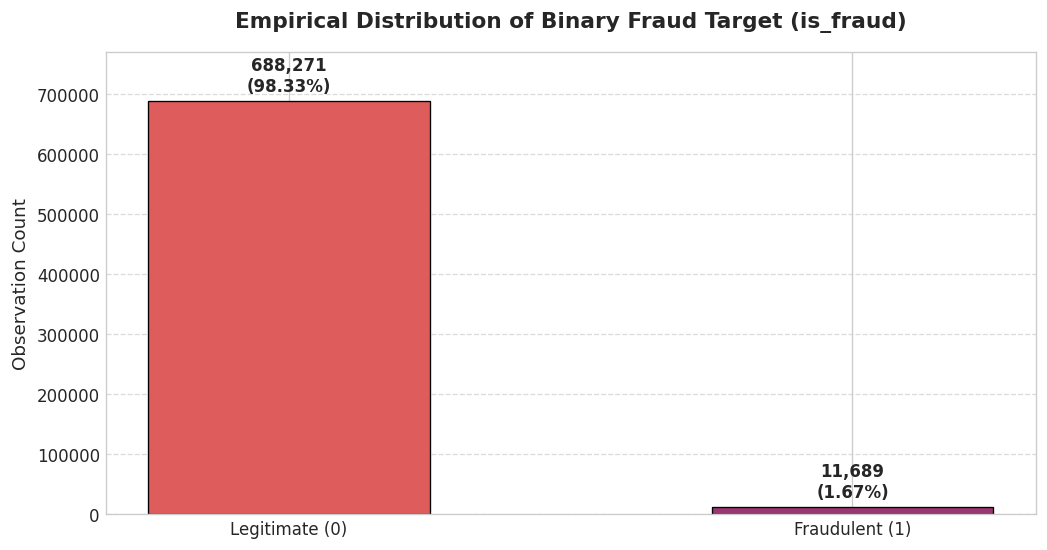

In [3]:
# Diagnostic Figure 1: Target Prevalence & Class Asymmetry
plt.figure(figsize=(10, 5), dpi=120)
palette = sns.color_palette("flare", n_colors=2)
counts = train_df['is_fraud'].value_counts().sort_index()
bars = plt.bar(['Legitimate (0)', 'Fraudulent (1)'], counts.values, color=palette, edgecolor='black', linewidth=0.8, width=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 10000,
             f"{height:,}\n({height/len(train_df)*100:.2f}%)",
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Empirical Distribution of Binary Fraud Target (is_fraud)", fontsize=13, fontweight='bold', pad=15)
plt.ylabel("Observation Count", fontsize=11)
plt.ylim(0, len(train_df) * 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


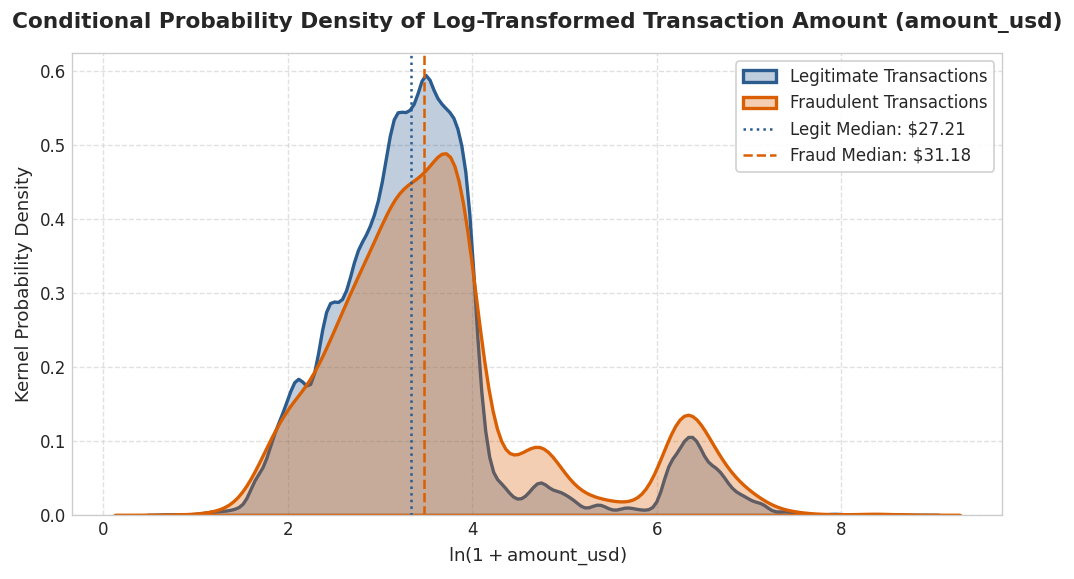

In [4]:
# Diagnostic Figure 2: Empirical Density of Log-Transformed Transaction Amount
plt.figure(figsize=(10, 5), dpi=120)
log_amt_legit = np.log1p(train_df.loc[train_df['is_fraud'] == 0, 'amount_usd'])
log_amt_fraud = np.log1p(train_df.loc[train_df['is_fraud'] == 1, 'amount_usd'])

sns.kdeplot(log_amt_legit, color='#2b5c8f', label='Legitimate Transactions', fill=True, alpha=0.3, linewidth=2.0)
sns.kdeplot(log_amt_fraud, color='#d95f02', label='Fraudulent Transactions', fill=True, alpha=0.3, linewidth=2.0)

plt.axvline(log_amt_legit.median(), color='#2b5c8f', linestyle=':', label=f'Legit Median: ${np.expm1(log_amt_legit.median()):.2f}')
plt.axvline(log_amt_fraud.median(), color='#d95f02', linestyle='--', label=f'Fraud Median: ${np.expm1(log_amt_fraud.median()):.2f}')

plt.title("Conditional Probability Density of Log-Transformed Transaction Amount (amount_usd)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel(r"$\ln(1 + \text{amount\_usd})$", fontsize=11)
plt.ylabel("Kernel Probability Density", fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


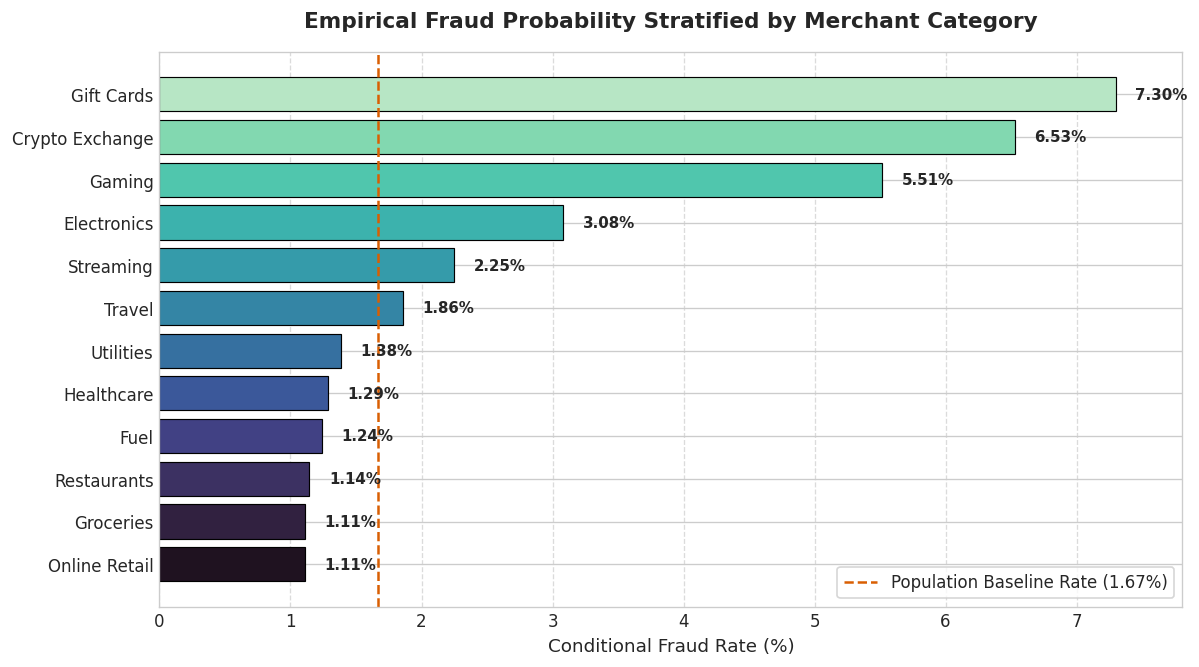

In [5]:
# Diagnostic Figure 3: Empirical Fraud Rate Across Merchant Categories
plt.figure(figsize=(11, 6), dpi=120)
cat_fraud = train_df.groupby('merchant_category')['is_fraud'].agg(['mean', 'count']).sort_values('mean', ascending=False)

palette = sns.color_palette("mako", n_colors=len(cat_fraud))
bars = plt.barh(cat_fraud.index[::-1], cat_fraud['mean'].values[::-1] * 100, color=palette, edgecolor='black', linewidth=0.7)

base_fraud_rate = train_df['is_fraud'].mean() * 100
plt.axvline(base_fraud_rate, color='#d95f02', linestyle='--', linewidth=1.5, label=f'Population Baseline Rate ({base_fraud_rate:.2f}%)')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.15, bar.get_y() + bar.get_height()/2.,
             f"{width:.2f}%", ha='left', va='center', fontsize=9, fontweight='bold')

plt.title("Empirical Fraud Probability Stratified by Merchant Category", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Conditional Fraud Rate (%)", fontsize=11)
plt.xlim(0, max(cat_fraud['mean'] * 100) * 1.07)
plt.legend(frameon=True, facecolor='white', loc='lower right', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


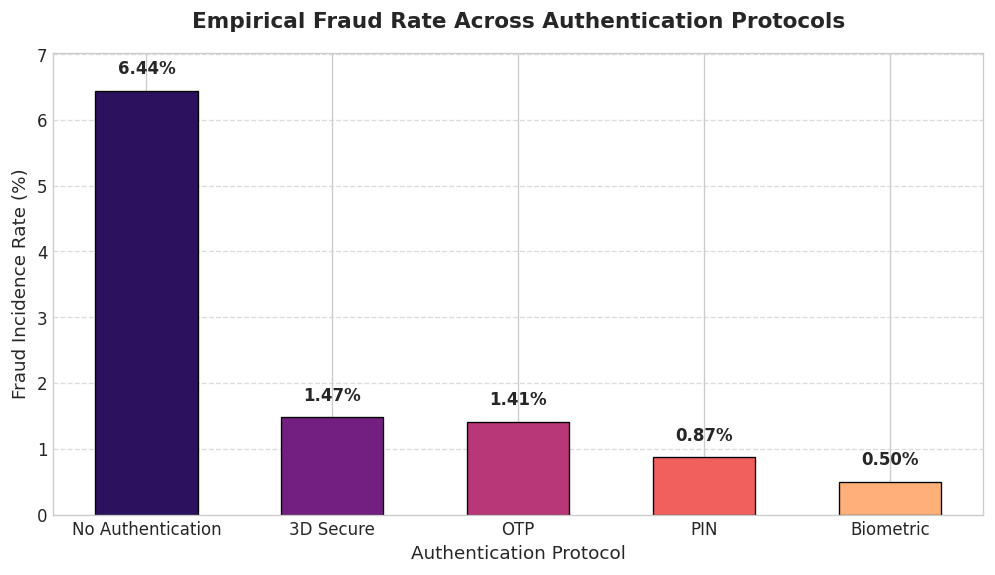

In [6]:
# Diagnostic Figure 4: Authentication Protocol Vulnerability Analysis
plt.figure(figsize=(10, 5), dpi=120)
auth_rates = train_df.groupby('auth_method')['is_fraud'].agg(['mean', 'count']).sort_values('mean', ascending=False)

palette = sns.color_palette("magma", n_colors=len(auth_rates))
bars = plt.bar(auth_rates.index, auth_rates['mean'].values * 100, color=palette, edgecolor='black', linewidth=0.8, width=0.55)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.2,
             f"{height:.2f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Empirical Fraud Rate Across Authentication Protocols", fontsize=13, fontweight='bold', pad=15)
plt.ylabel("Fraud Incidence Rate (%)", fontsize=11)
plt.xlabel("Authentication Protocol", fontsize=11)
plt.ylim(0, max(auth_rates['mean'] * 100) * 1.09)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


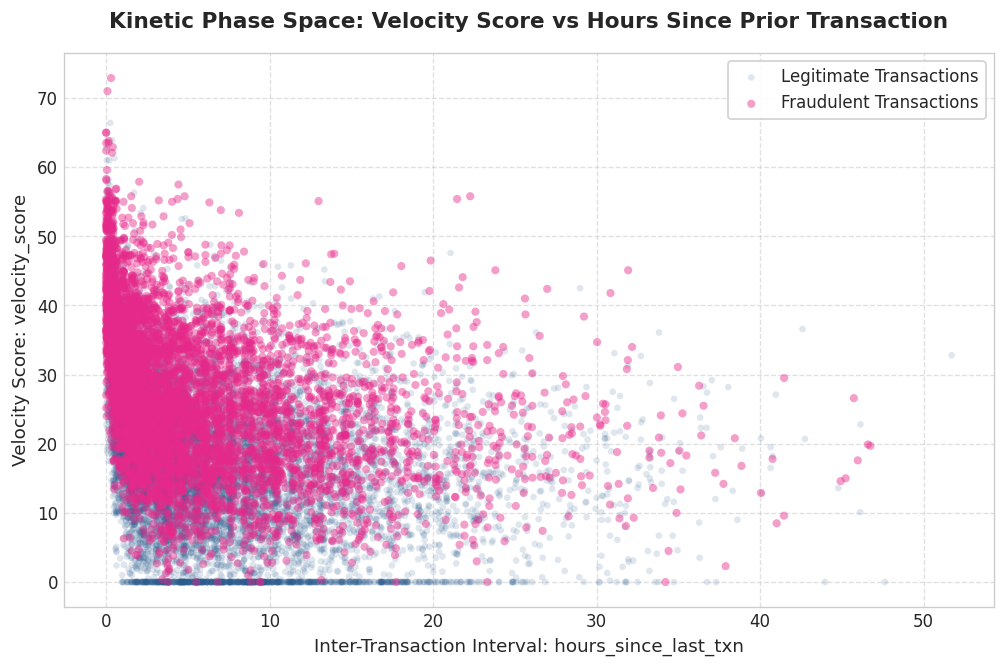

In [7]:
# Diagnostic Figure 5: Kinetic Phase Space: Velocity Score vs Inter-Transaction Temporal Interval
plt.figure(figsize=(10, 6), dpi=120)
sample_legit = train_df[train_df['is_fraud'] == 0].sample(n=12000, random_state=SEED)
sample_fraud = train_df[train_df['is_fraud'] == 1].sample(n=min(len(train_df[train_df['is_fraud'] == 1]), 6000), random_state=SEED)

plt.scatter(sample_legit['hours_since_last_txn'], sample_legit['velocity_score'],
            c='#2b5c8f', alpha=0.15, s=16, label='Legitimate Transactions', edgecolors='none')
plt.scatter(sample_fraud['hours_since_last_txn'], sample_fraud['velocity_score'],
            c='#e7298a', alpha=0.45, s=24, label='Fraudulent Transactions', edgecolors='none')

plt.title("Kinetic Phase Space: Velocity Score vs Hours Since Prior Transaction", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Inter-Transaction Interval: hours_since_last_txn", fontsize=11)
plt.ylabel("Velocity Score: velocity_score", fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


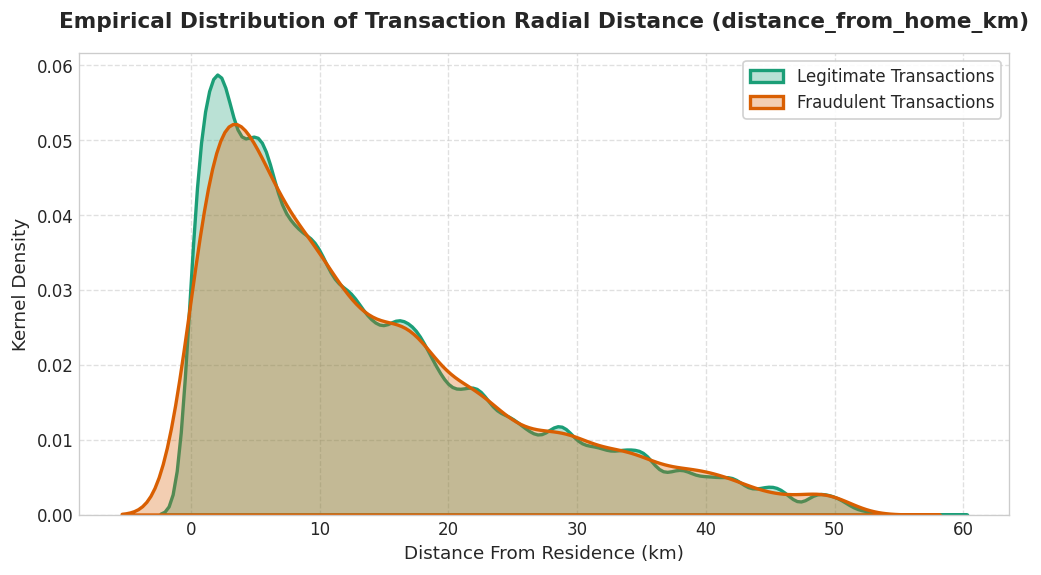

In [8]:
# Diagnostic Figure 6: Spatial Displacement Distribution Conditional on Target
plt.figure(figsize=(10, 5), dpi=120)
sns.kdeplot(train_df.loc[train_df['is_fraud'] == 0, 'distance_from_home_km'],
            color='#1b9e77', label='Legitimate Transactions', fill=True, alpha=0.3, linewidth=2.0)
sns.kdeplot(train_df.loc[train_df['is_fraud'] == 1, 'distance_from_home_km'],
            color='#d95f02', label='Fraudulent Transactions', fill=True, alpha=0.3, linewidth=2.0)

plt.title("Empirical Distribution of Transaction Radial Distance (distance_from_home_km)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Distance From Residence (km)", fontsize=11)
plt.ylabel("Kernel Density", fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


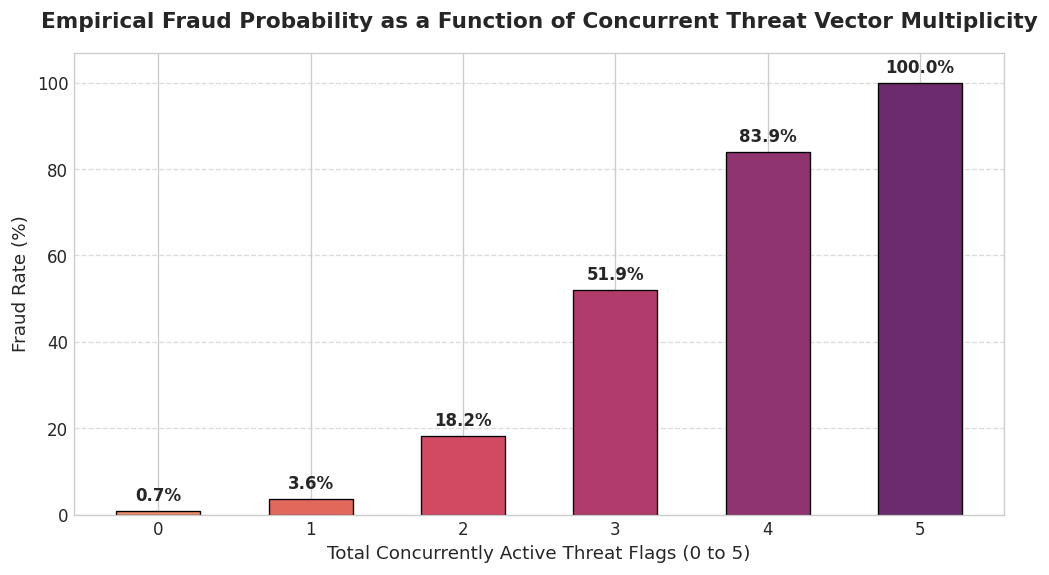

In [9]:
# Diagnostic Figure 7: Cyber-Threat Vector Multiplication and Exponential Risk Escalation
plt.figure(figsize=(10, 5), dpi=120)
threat_cols = ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 
               'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']

train_df['temp_threat_sum'] = train_df[threat_cols].sum(axis=1)
threat_stats = train_df.groupby('temp_threat_sum')['is_fraud'].agg(['mean', 'count'])

palette = sns.color_palette("flare", n_colors=len(threat_stats))
bars = plt.bar(threat_stats.index.astype(str), threat_stats['mean'].values * 100, color=palette, edgecolor='black', linewidth=0.8, width=0.55)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1.5,
             f"{height:.1f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Empirical Fraud Probability as a Function of Concurrent Threat Vector Multiplicity", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Total Concurrently Active Threat Flags (0 to 5)", fontsize=11)
plt.ylabel("Fraud Rate (%)", fontsize=11)
plt.ylim(0, 107)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

train_df.drop(columns=['temp_threat_sum'], inplace=True)


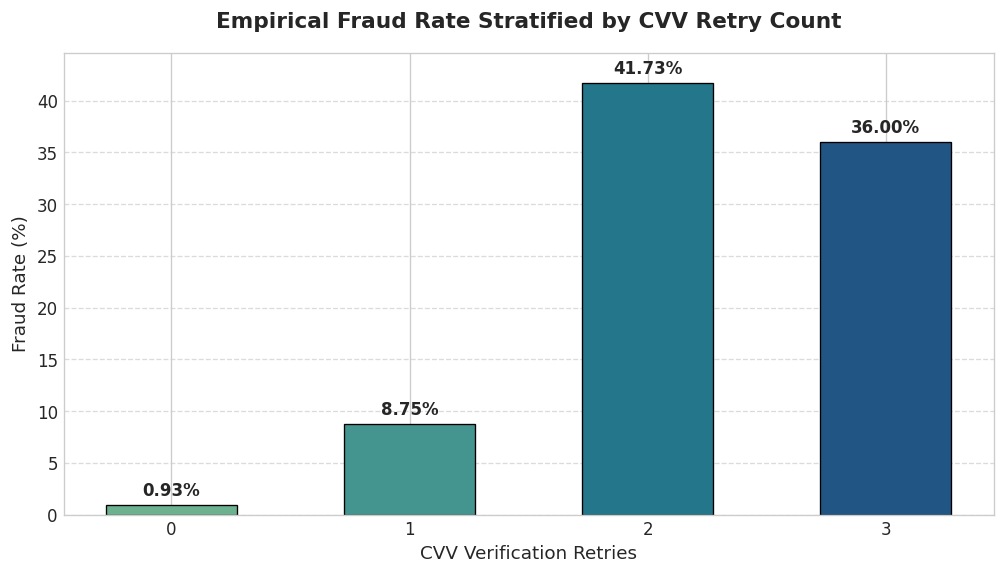

In [10]:
# Diagnostic Figure 8: Cardholder Verification Failure Dynamics (cvv_retry_count)
plt.figure(figsize=(10, 5), dpi=120)
cvv_rates = train_df.groupby('cvv_retry_count')['is_fraud'].agg(['mean', 'count'])

palette = sns.color_palette("crest", n_colors=len(cvv_rates))
bars = plt.bar(cvv_rates.index.astype(str), cvv_rates['mean'].values * 100, color=palette, edgecolor='black', linewidth=0.8, width=0.55)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.5,
             f"{height:.2f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Empirical Fraud Rate Stratified by CVV Retry Count", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("CVV Verification Retries", fontsize=11)
plt.ylabel("Fraud Rate (%)", fontsize=11)
plt.ylim(0, max(cvv_rates['mean'] * 100) * 1.07)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


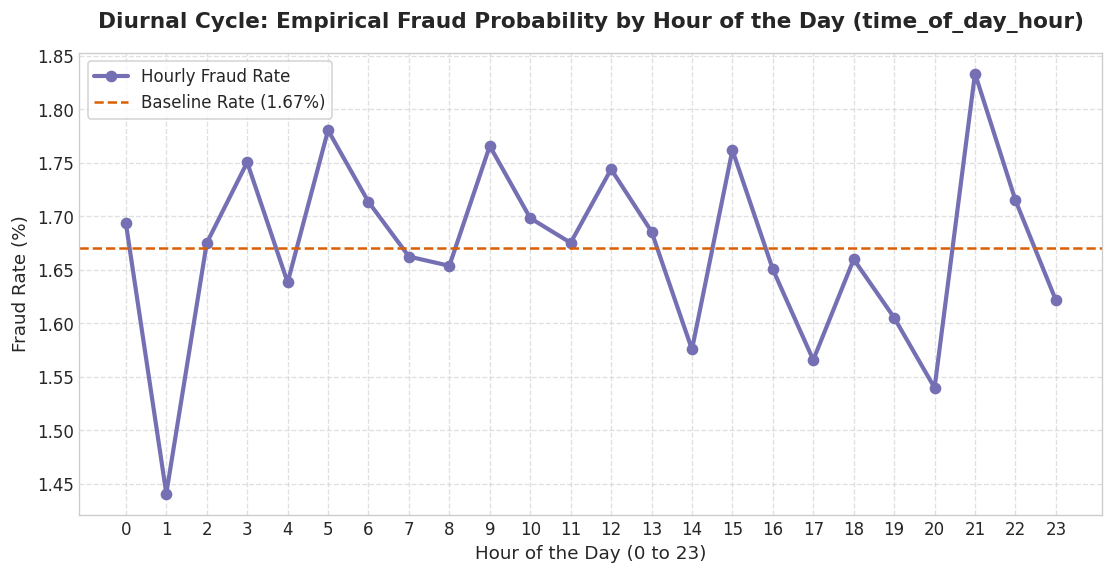

In [11]:
# Diagnostic Figure 9: Diurnal Seasonality Across 24-Hour Solar Cycle
plt.figure(figsize=(11, 5), dpi=120)
hourly_stats = train_df.groupby('time_of_day_hour')['is_fraud'].agg(['mean', 'count'])

plt.plot(hourly_stats.index, hourly_stats['mean'].values * 100, marker='o', linewidth=2.5,
         markersize=6, color='#7570b3', label='Hourly Fraud Rate')

plt.axhline(base_fraud_rate, color='#d95f02', linestyle='--', label=f'Baseline Rate ({base_fraud_rate:.2f}%)')

plt.title("Diurnal Cycle: Empirical Fraud Probability by Hour of the Day (time_of_day_hour)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Hour of the Day (0 to 23)", fontsize=11)
plt.ylabel("Fraud Rate (%)", fontsize=11)
plt.xticks(np.arange(0, 24, 1))
plt.legend(frameon=True, facecolor='white', loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


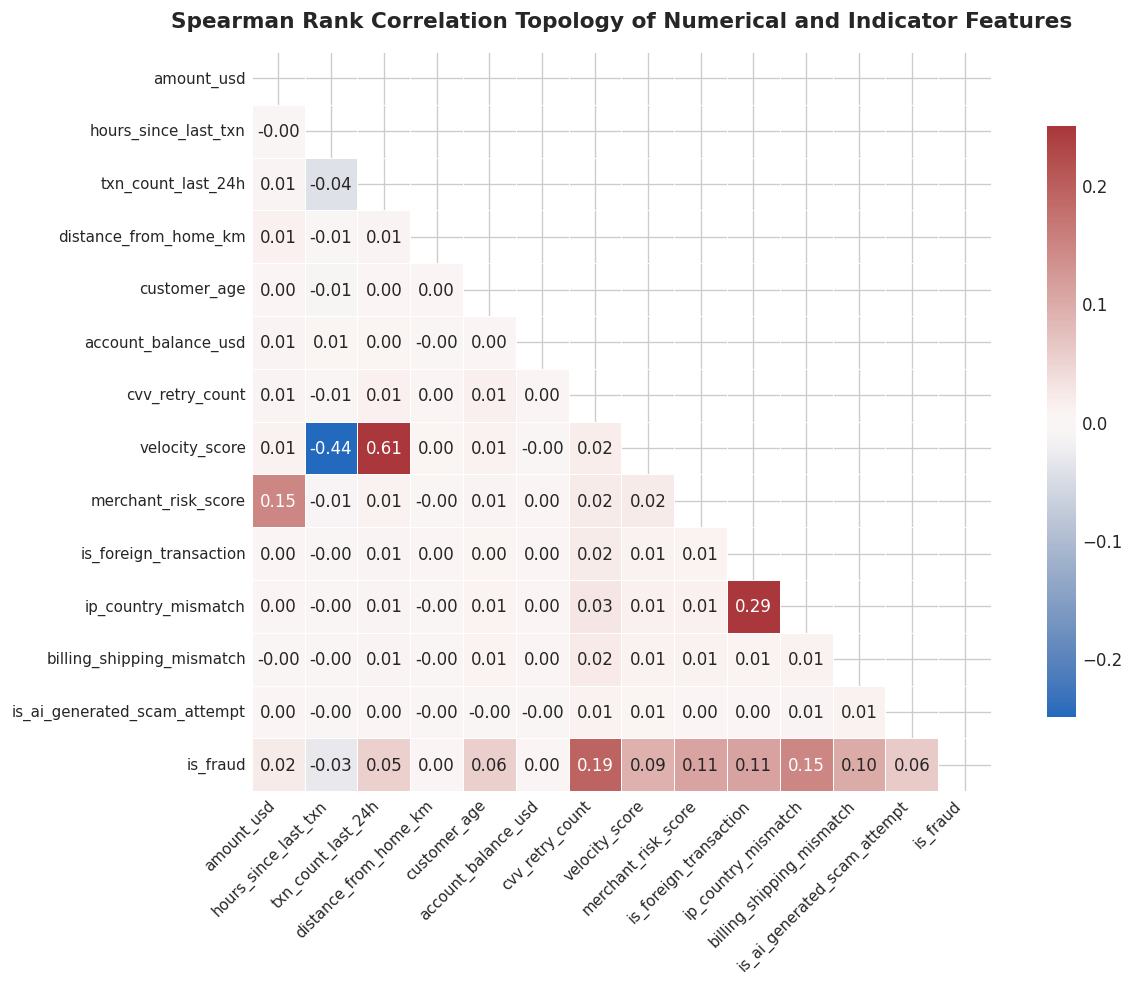

In [12]:
# Diagnostic Figure 10: Linear and Monotonic Correlation Matrix
plt.figure(figsize=(12, 8), dpi=120)
num_candidates = ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 
                  'distance_from_home_km', 'customer_age', 'account_balance_usd', 
                  'cvv_retry_count', 'velocity_score', 'merchant_risk_score', 
                  'is_foreign_transaction', 'ip_country_mismatch', 
                  'billing_shipping_mismatch', 'is_ai_generated_scam_attempt', 'is_fraud']

corr_matrix = train_df[num_candidates].astype(float).corr(method='spearman')

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='vlag', vmin=-0.25, vmax=0.25, center=0,
            annot=True, fmt=".2f", square=True, linewidths=0.6, cbar_kws={"shrink": 0.8})

plt.title("Spearman Rank Correlation Topology of Numerical and Indicator Features", fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.show()


# 5. Physics-Informed & Domain-Specific Mathematical Feature Engineering

## 5.1 Kinematic and Hydrodynamic Analogies

1. **Transaction Kinetic Energy / Momentum Proxy:** Interpreting transaction magnitude as an operational inertial mass and velocity score as state velocity:
   $$E_{\text{kinetic}} = \frac{1}{2} \cdot \text{amount\_usd} \cdot (\text{velocity\_score})^2$$

2. **Spatial Displacement Velocity Proxy:** Apparent physical transit speed required to execute sequential transactions:
   $$v_{\text{spatial}} = \frac{\text{distance\_from\_home\_km}}{\text{hours\_since\_last\_txn} + \epsilon}$$
   Superluminal physical displacement signals distributed adversary attacks.

3. **Transaction Flux Density:** Discrete transaction volume per temporal interval:
   $$\Phi_{\text{txn}} = \frac{\text{txn\_count\_last\_24h}}{\text{hours\_since\_last\_txn} + \epsilon}$$

## 5.2 Financial Leverage & Liquidity Depletion Ratios

1. **Liquidity Exhaustion Ratio:**
   $$\mathcal{R}_{\text{leverage}} = \frac{\text{amount\_usd}}{\text{account\_balance\_usd} + 1.0}$$

2. **Absolute Liquidity Deficit:**
   $$\Delta_{\text{liquidity}} = \text{amount\_usd} - \text{account\_balance\_usd}$$

## 5.3 Cyber-Threat Vector Multiplicity & Empirical Scoring

Let $\mathcal{T} = \{\text{foreign}, \text{new\_merchant}, \text{vpn}, \text{ip\_mismatch}, \text{billing\_mismatch}, \text{ai\_scam}\}$:

1. **Unweighted Threat Multiplicity:**
   $$\mathcal{I}_{\text{threat}} = \sum_{k \in \mathcal{T}} \mathbb{I}_k$$

2. **Empirical Bayesian Threat Index:**
   $$\mathcal{W}_{\text{threat}} = 2.5 \cdot \text{cvv} + 3.0 \cdot \text{ip\_mismatch} + 3.0 \cdot \text{ai\_scam} + 2.5 \cdot \text{billing\_mismatch} + 2.5 \cdot \text{foreign} + 1.5 \cdot \text{vpn} + 1.5 \cdot \text{new\_merchant}$$

3. **Risk-Weighted Amount Exposure:**
   $$\mathcal{E}_{\text{risk}} = \text{amount\_usd} \times \left( \frac{\text{merchant\_risk\_score}}{100.0} \right)$$

## 5.4 Harmonic Trigonometric Embeddings

Mapping periodic solar hours and weekly days to continuous Euclidean coordinates on $S^1$:
$$\mathbf{e}_{\text{hour}} = \left[ \sin\left(\frac{2\pi \cdot \text{hour}}{24}\right), \cos\left(\frac{2\pi \cdot \text{hour}}{24}\right) \right]^T, \quad \mathbf{e}_{\text{day}} = \left[ \sin\left(\frac{2\pi \cdot \text{day}}{7}\right), \cos\left(\frac{2\pi \cdot \text{day}}{7}\right) \right]^T$$

## 5.5 Group-Conditional Standardized Residuals

Category-conditional deviations computed strictly from the reference training set:
$$z_{\text{amt} \mid \text{cat}} = \frac{\text{amount\_usd} - \mu_{\text{cat}}}{\sigma_{\text{cat}} + \epsilon}$$

In [13]:
# Compute category-conditional priors strictly from the training partition to prevent test contamination
group_stats = train_df.groupby('merchant_category')['amount_usd'].agg(['mean', 'std']).reset_index()
group_stats.columns = ['merchant_category', 'cat_amt_mean', 'cat_amt_std']

def construct_feature_matrix(df, group_priors):
    d = df.copy()
    eps = 0.05
    
    # Cast boolean threat indicators to integer representations
    threat_cols = ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 
                   'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']
    for c in threat_cols:
        d[c] = d[c].astype(np.int32)
        
    # Unweighted composite threat multiplicity
    d['composite_risk_flags'] = d[threat_cols].sum(axis=1).astype(np.int32)
    
    # Empirical Bayesian threat index
    d['weighted_threat_index'] = (
        d['cvv_retry_count'] * 2.5 + 
        d['ip_country_mismatch'] * 3.0 + 
        d['is_ai_generated_scam_attempt'] * 3.0 +
        d['billing_shipping_mismatch'] * 2.5 +
        d['is_foreign_transaction'] * 2.5 +
        d['used_vpn'] * 1.5 +
        d['is_new_merchant'] * 1.5
    ).astype(np.float32)
    
    # Financial leverage and liquidity metrics
    d['amount_to_balance_ratio'] = (d['amount_usd'] / (d['account_balance_usd'] + 1.0)).astype(np.float32)
    d['amount_balance_discrepancy'] = (d['amount_usd'] - d['account_balance_usd']).astype(np.float32)
    d['log_amount'] = np.log1p(d['amount_usd']).astype(np.float32)
    d['log_balance'] = np.log1p(d['account_balance_usd']).astype(np.float32)
    
    # Kinematic momentum and displacement speed proxies
    d['kinetic_energy_proxy'] = (0.5 * d['amount_usd'] * (d['velocity_score'] ** 2)).astype(np.float32)
    d['spatial_speed_proxy'] = (d['distance_from_home_km'] / (d['hours_since_last_txn'] + eps)).astype(np.float32)
    d['transaction_flux_density'] = (d['txn_count_last_24h'] / (d['hours_since_last_txn'] + eps)).astype(np.float32)
    d['velocity_per_hour'] = (d['velocity_score'] / (d['hours_since_last_txn'] + eps)).astype(np.float32)
    
    # Cross-product risk exposures
    d['amount_risk_exposure'] = (d['amount_usd'] * (d['merchant_risk_score'] / 100.0)).astype(np.float32)
    d['velocity_risk_exposure'] = (d['velocity_score'] * (d['merchant_risk_score'] / 100.0)).astype(np.float32)
    d['cvv_merchant_risk_interaction'] = (d['cvv_retry_count'] * d['merchant_risk_score']).astype(np.float32)
    
    # Periodic trigonometric diurnal and hebdomadal embeddings
    d['sin_hour'] = np.sin(2.0 * np.pi * d['time_of_day_hour'] / 24.0).astype(np.float32)
    d['cos_hour'] = np.cos(2.0 * np.pi * d['time_of_day_hour'] / 24.0).astype(np.float32)
    d['sin_day'] = np.sin(2.0 * np.pi * d['day_of_week'] / 7.0).astype(np.float32)
    d['cos_day'] = np.cos(2.0 * np.pi * d['day_of_week'] / 7.0).astype(np.float32)
    d['is_weekend'] = d['day_of_week'].isin([5, 6]).astype(np.int32)
    d['is_nocturnal'] = d['time_of_day_hour'].isin([0, 1, 2, 3, 4, 5]).astype(np.int32)
    
    # Cardholder tenure interaction
    d['card_to_cust_age_ratio'] = (d['card_age_months'] / ((d['customer_age'] * 12.0) + 1.0)).astype(np.float32)
    
    # Merge category-conditional priors
    d = d.merge(group_priors, on='merchant_category', how='left')
    d['amt_cat_diff'] = (d['amount_usd'] - d['cat_amt_mean']).astype(np.float32)
    d['amt_cat_zscore'] = ((d['amount_usd'] - d['cat_amt_mean']) / (d['cat_amt_std'] + 1e-4)).astype(np.float32)
    
    return d

train_fe = construct_feature_matrix(train_df, group_stats)
test_fe = construct_feature_matrix(test_df, group_stats)

# Categorical column definitions
cat_cols = ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

# Label encode categorical columns for homogeneous tree inputs
for c in cat_cols:
    train_fe[c] = train_fe[c].astype('category')
    test_fe[c] = test_fe[c].astype('category')

feature_cols = [c for c in train_fe.columns if c not in ['id', 'is_fraud']]
target_col = 'is_fraud'

print(f"Feature Engineering Complete:")
print(f"  Total Engineered Features: {len(feature_cols)}")
print(f"  Categorical Feature Count: {len(cat_cols)}")
print(f"  Numerical / Kinetic Count: {len(feature_cols) - len(cat_cols)}")


Feature Engineering Complete:
  Total Engineered Features: 48
  Categorical Feature Count: 5
  Numerical / Kinetic Count: 43


# 6. Validation Framework: Stratified K-Fold Partitioning

A 5-fold stratified cross-validation partitioning scheme is established with fixed random seeding:
$$\mathcal{D} = \bigcup_{k=1}^K \mathcal{D}_k^{\text{val}}, \quad \mathcal{D}_k^{\text{train}} = \mathcal{D} \setminus \mathcal{D}_k^{\text{val}}, \quad \frac{|\mathcal{D}_k^{\text{val}} \cap \{y=1\}|}{|\mathcal{D}_k^{\text{val}}|} \approx \pi$$

Out-of-fold probability containers are allocated for each model family to facilitate unbiased out-of-sample blending.

In [14]:
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

X = train_fe[feature_cols].copy()
y = train_fe[target_col].values.astype(np.int32)
X_test = test_fe[feature_cols].copy()

# Initialize out-of-fold probability arrays
oof_lgb = np.zeros(len(train_fe), dtype=np.float32)
oof_xgb = np.zeros(len(train_fe), dtype=np.float32)
oof_cb  = np.zeros(len(train_fe), dtype=np.float32)
oof_nn  = np.zeros(len(train_fe), dtype=np.float32)

# Initialize test set accumulation arrays
preds_test_lgb = np.zeros(len(test_fe), dtype=np.float32)
preds_test_xgb = np.zeros(len(test_fe), dtype=np.float32)
preds_test_cb  = np.zeros(len(test_fe), dtype=np.float32)
preds_test_nn  = np.zeros(len(test_fe), dtype=np.float32)

print(f"Validation Harness Configured: {N_SPLITS}-Fold Stratified Partitioning across {len(X):,} observations.")


Validation Harness Configured: 5-Fold Stratified Partitioning across 699,960 observations.


# 7. Model Family 1: LightGBM Gradient Boosted Decision Trees

LightGBM minimizes empirical binary cross-entropy loss via leaf-wise histogram tree expansion with gradient-based one-side sampling:
$$\mathcal{L}_{\text{BCE}}(y, \hat{p}) = -\sum_{i=1}^N \left[ y_i \ln \hat{p}_i + (1 - y_i) \ln (1 - \hat{p}_i) \right]$$

Hyperparameters are tuned to regularize leaf complexity: `learning_rate=0.03`, `num_leaves=42`, `max_depth=7`, `min_child_samples=50`, with L1 (`reg_alpha=1.0`) and L2 (`reg_lambda=5.0`) penalties.

In [15]:
# Configure LightGBM hyperparameters
lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'learning_rate': 0.03,
    'num_leaves': 42,
    'max_depth': 7,
    'min_child_samples': 50,
    'subsample': 0.85,
    'colsample_bytree': 0.80,
    'reg_alpha': 1.0,
    'reg_lambda': 5.0,
    'random_state': SEED,
    'n_estimators': 1500,
    'verbose': -1,
    'n_jobs': -1
}

lgb_feature_importances = np.zeros(len(feature_cols), dtype=np.float64)

print("Training Model Family 1: LightGBM (5-Fold Stratified Cross-Validation)...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train_f, y_train_f = X.iloc[train_idx], y[train_idx]
    X_val_f, y_val_f = X.iloc[val_idx], y[val_idx]
    
    model_lgb = lgb.LGBMClassifier(**lgb_params)
    model_lgb.fit(
        X_train_f, y_train_f,
        eval_set=[(X_val_f, y_val_f)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    
    val_preds = model_lgb.predict_proba(X_val_f)[:, 1]
    oof_lgb[val_idx] = val_preds
    preds_test_lgb += model_lgb.predict_proba(X_test)[:, 1] / N_SPLITS
    lgb_feature_importances += model_lgb.feature_importances_ / N_SPLITS
    
    fold_auc = roc_auc_score(y_val_f, val_preds)
    print(f"  Fold {fold + 1}/{N_SPLITS} Validation ROC-AUC: {fold_auc:.5f} (Best Iteration: {model_lgb.best_iteration_})")

total_lgb_auc = roc_auc_score(y, oof_lgb)
print(f"LightGBM Out-of-Fold Global ROC-AUC: {total_lgb_auc:.5f}")


Training Model Family 1: LightGBM (5-Fold Stratified Cross-Validation)...
  Fold 1/5 Validation ROC-AUC: 0.94415 (Best Iteration: 485)
  Fold 2/5 Validation ROC-AUC: 0.94757 (Best Iteration: 407)
  Fold 3/5 Validation ROC-AUC: 0.95081 (Best Iteration: 527)
  Fold 4/5 Validation ROC-AUC: 0.94634 (Best Iteration: 392)
  Fold 5/5 Validation ROC-AUC: 0.94152 (Best Iteration: 575)
LightGBM Out-of-Fold Global ROC-AUC: 0.94600


# 8. Model Family 2: GPU-Accelerated XGBoost Classifier

XGBoost implements exact second-order Taylor expansions of the objective function, executed using the GPU histogram method (`tree_method='hist'`) for hardware acceleration. Depth-wise tree building with conservative splitting parameters ($\gamma=0.5, \alpha=1.0, \lambda=5.0$) yields functional divergence from LightGBM.

In [16]:
# Configure XGBoost hyperparameters
xgb_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'tree_method': 'hist',
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'learning_rate': 0.03,
    'max_depth': 6,
    'min_child_weight': 30,
    'subsample': 0.85,
    'colsample_bytree': 0.80,
    'gamma': 0.5,
    'reg_alpha': 1.0,
    'reg_lambda': 5.0,
    'random_state': SEED,
    'n_estimators': 1500,
    'enable_categorical': True
}

xgb_feature_importances = np.zeros(len(feature_cols), dtype=np.float64)

print("Training Model Family 2: XGBoost (5-Fold Stratified Cross-Validation)...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train_f, y_train_f = X.iloc[train_idx], y[train_idx]
    X_val_f, y_val_f = X.iloc[val_idx], y[val_idx]
    
    model_xgb = xgb.XGBClassifier(**xgb_params)
    model_xgb.fit(
        X_train_f, y_train_f,
        eval_set=[(X_val_f, y_val_f)],
        verbose=False
    )
    
    val_preds = model_xgb.predict_proba(X_val_f)[:, 1]
    oof_xgb[val_idx] = val_preds
    preds_test_xgb += model_xgb.predict_proba(X_test)[:, 1] / N_SPLITS
    xgb_feature_importances += model_xgb.feature_importances_ / N_SPLITS
    
    fold_auc = roc_auc_score(y_val_f, val_preds)
    print(f"  Fold {fold + 1}/{N_SPLITS} Validation ROC-AUC: {fold_auc:.5f}")

total_xgb_auc = roc_auc_score(y, oof_xgb)
print(f"XGBoost Out-of-Fold Global ROC-AUC: {total_xgb_auc:.5f}")


Training Model Family 2: XGBoost (5-Fold Stratified Cross-Validation)...
  Fold 1/5 Validation ROC-AUC: 0.94344
  Fold 2/5 Validation ROC-AUC: 0.94765
  Fold 3/5 Validation ROC-AUC: 0.95061
  Fold 4/5 Validation ROC-AUC: 0.94537
  Fold 5/5 Validation ROC-AUC: 0.94048
XGBoost Out-of-Fold Global ROC-AUC: 0.94547


# 9. Model Family 3: CatBoost Symmetric Decision Trees

CatBoost employs symmetric (oblivious) decision trees where identical splitting criteria are applied across all nodes at a given depth. This architecture acts as an inductive regularizer against over-partitioning rare categorical states.

In [17]:
# Prepare inputs for CatBoost
X_cb = X.copy()
X_test_cb = X_test.copy()
for c in cat_cols:
    X_cb[c] = X_cb[c].astype(str)
    X_test_cb[c] = X_test_cb[c].astype(str)

cb_params = {
    'loss_function': 'Logloss',
    'eval_metric': 'AUC',
    'iterations': 1200,
    'learning_rate': 0.04,
    'depth': 6,
    'l2_leaf_reg': 5.0,
    'random_seed': SEED,
    'verbose': False,
    'task_type': 'GPU' if torch.cuda.is_available() else 'CPU',
    'cat_features': cat_cols
}

print("Training Model Family 3: CatBoost (5-Fold Stratified Cross-Validation)...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_cb, y)):
    X_train_f, y_train_f = X_cb.iloc[train_idx], y[train_idx]
    X_val_f, y_val_f = X_cb.iloc[val_idx], y[val_idx]
    
    model_cb = cb.CatBoostClassifier(**cb_params)
    model_cb.fit(
        X_train_f, y_train_f,
        eval_set=(X_val_f, y_val_f),
        early_stopping_rounds=50,
        verbose=False
    )
    
    val_preds = model_cb.predict_proba(X_val_f)[:, 1]
    oof_cb[val_idx] = val_preds
    preds_test_cb += model_cb.predict_proba(X_test_cb)[:, 1] / N_SPLITS
    
    fold_auc = roc_auc_score(y_val_f, val_preds)
    print(f"  Fold {fold + 1}/{N_SPLITS} Validation ROC-AUC: {fold_auc:.5f}")

total_cb_auc = roc_auc_score(y, oof_cb)
print(f"CatBoost Out-of-Fold Global ROC-AUC: {total_cb_auc:.5f}")


Training Model Family 3: CatBoost (5-Fold Stratified Cross-Validation)...


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 1/5 Validation ROC-AUC: 0.94142


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 2/5 Validation ROC-AUC: 0.94524


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 3/5 Validation ROC-AUC: 0.94839


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 4/5 Validation ROC-AUC: 0.94320


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 5/5 Validation ROC-AUC: 0.93947
CatBoost Out-of-Fold Global ROC-AUC: 0.94348


# 10. Model Family 4: Deep Residual Tabular Neural Network with Entity Embeddings

To project non-linear continuous interactions and dense latent manifolds that orthogonal tree splits fail to represent smoothly:
1. **Entity Embeddings:** Categorical variables are mapped to learned continuous vectors: $\mathbf{e}_c \in \mathbb{R}^{d_c}$.
2. **Dense Residual Backbone:** The concatenated numerical and embedded vector is processed through residual skip blocks with Batch Normalization, SiLU non-linearities, and Dropout:
   $$\mathbf{h}_{l+1} = \text{SiLU}\left( \text{BN}\left( \mathbf{W}_{l,2} \text{SiLU}\left( \text{BN}\left( \mathbf{W}_{l,1} \mathbf{h}_l \right) \right) \right) \right) + \mathbf{h}_l$$
3. **Imbalance-Weighted Optimization:** Binary Cross-Entropy with class reweighting, optimized via AdamW with Cosine Annealing.

In [18]:
# Prepare numerical scaling and categorical indices for PyTorch Tabular ResNet
num_features = [c for c in feature_cols if c not in cat_cols]
scaler = RobustScaler()
X_num_scaled = scaler.fit_transform(X[num_features]).astype(np.float32)
X_test_num_scaled = scaler.transform(X_test[num_features]).astype(np.float32)

cat_cardinalities = [len(train_fe[c].cat.categories) for c in cat_cols]
emb_dimensions = [min(16, max(4, (card + 1) // 2)) for card in cat_cardinalities]

X_cat_indices = np.column_stack([X[c].cat.codes.values for c in cat_cols]).astype(np.int64)
X_test_cat_indices = np.column_stack([X_test[c].cat.codes.values for c in cat_cols]).astype(np.int64)

class TabularResNet(nn.Module):
    def __init__(self, num_dim, cardinalities, emb_dims, hidden_dim=128, dropout=0.2):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(card, dim) for card, dim in zip(cardinalities, emb_dims)
        ])
        total_in_dim = num_dim + sum(emb_dims)
        
        self.input_layer = nn.Sequential(
            nn.Linear(total_in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout)
        )
        
        # Residual Block 1
        self.res1_fc1 = nn.Linear(hidden_dim, hidden_dim)
        self.res1_bn1 = nn.BatchNorm1d(hidden_dim)
        self.res1_fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.res1_bn2 = nn.BatchNorm1d(hidden_dim)
        
        # Residual Block 2
        self.res2_fc1 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.res2_bn1 = nn.BatchNorm1d(hidden_dim // 2)
        self.res2_skip = nn.Linear(hidden_dim, hidden_dim // 2)
        self.res2_fc2 = nn.Linear(hidden_dim // 2, hidden_dim // 2)
        self.res2_bn2 = nn.BatchNorm1d(hidden_dim // 2)
        
        self.head = nn.Sequential(
            nn.Linear(hidden_dim // 2, 32),
            nn.BatchNorm1d(32),
            nn.SiLU(),
            nn.Dropout(dropout / 2.0),
            nn.Linear(32, 1)
        )
        self.act = nn.SiLU()

    def forward(self, x_num, x_cat):
        emb_outs = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]
        x = torch.cat([x_num] + emb_outs, dim=1)
        h = self.input_layer(x)
        
        # Residual 1
        res = h
        h = self.act(self.res1_bn1(self.res1_fc1(h)))
        h = self.res1_bn2(self.res1_fc2(h))
        h = self.act(h + res)
        
        # Residual 2
        res = self.res2_skip(h)
        h = self.act(self.res2_bn1(self.res2_fc1(h)))
        h = self.res2_bn2(self.res2_fc2(h))
        h = self.act(h + res)
        
        return self.head(h).squeeze(-1)

class TabularDataset(Dataset):
    def __init__(self, x_num, x_cat, y=None):
        self.x_num = torch.tensor(x_num, dtype=torch.float32)
        self.x_cat = torch.tensor(x_cat, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32) if y is not None else None

    def __len__(self):
        return len(self.x_num)

    def __getitem__(self, idx):
        if self.y is not None:
            return self.x_num[idx], self.x_cat[idx], self.y[idx]
        return self.x_num[idx], self.x_cat[idx]

print("Training Model Family 4: Tabular ResNet (5-Fold Stratified Cross-Validation)...")
test_dataset = TabularDataset(X_test_num_scaled, X_test_cat_indices)
test_loader = DataLoader(test_dataset, batch_size=4096, shuffle=False)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    train_dataset = TabularDataset(X_num_scaled[train_idx], X_cat_indices[train_idx], y[train_idx])
    val_dataset = TabularDataset(X_num_scaled[val_idx], X_cat_indices[val_idx], y[val_idx])
    
    train_loader = DataLoader(train_dataset, batch_size=2048, shuffle=True, drop_last=True)
    val_loader = DataLoader(val_dataset, batch_size=4096, shuffle=False)
    
    model_nn = TabularResNet(len(num_features), cat_cardinalities, emb_dimensions).to(device)
    optimizer = torch.optim.AdamW(model_nn.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=8)
    
    best_val_auc = 0.0
    best_val_preds = None
    
    for epoch in range(8):
        model_nn.train()
        for batch_num, batch_cat, batch_y in train_loader:
            batch_num, batch_cat, batch_y = batch_num.to(device), batch_cat.to(device), batch_y.to(device)
            optimizer.zero_grad()
            logits = model_nn(batch_num, batch_cat)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()
        scheduler.step()
        
        # Validation evaluation
        model_nn.eval()
        val_preds_list = []
        with torch.no_grad():
            for batch_num, batch_cat, _ in val_loader:
                batch_num, batch_cat = batch_num.to(device), batch_cat.to(device)
                preds = torch.sigmoid(model_nn(batch_num, batch_cat)).cpu().numpy()
                val_preds_list.extend(preds)
        
        epoch_auc = roc_auc_score(y[val_idx], val_preds_list)
        if epoch_auc > best_val_auc:
            best_val_auc = epoch_auc
            best_val_preds = np.array(val_preds_list)
            
    oof_nn[val_idx] = best_val_preds
    
    # Test inference for fold
    model_nn.eval()
    fold_test_preds = []
    with torch.no_grad():
        for batch_num, batch_cat in test_loader:
            batch_num, batch_cat = batch_num.to(device), batch_cat.to(device)
            preds = torch.sigmoid(model_nn(batch_num, batch_cat)).cpu().numpy()
            fold_test_preds.extend(preds)
    preds_test_nn += np.array(fold_test_preds) / N_SPLITS
    
    print(f"  Fold {fold + 1}/{N_SPLITS} Validation ROC-AUC: {best_val_auc:.5f}")

total_nn_auc = roc_auc_score(y, oof_nn)
print(f"Tabular ResNet Out-of-Fold Global ROC-AUC: {total_nn_auc:.5f}")


Training Model Family 4: Tabular ResNet (5-Fold Stratified Cross-Validation)...
  Fold 1/5 Validation ROC-AUC: 0.94155
  Fold 2/5 Validation ROC-AUC: 0.94405
  Fold 3/5 Validation ROC-AUC: 0.94728
  Fold 4/5 Validation ROC-AUC: 0.94246
  Fold 5/5 Validation ROC-AUC: 0.93756
Tabular ResNet Out-of-Fold Global ROC-AUC: 0.94247


# 11. Ensemble Optimization & Meta-Learning Strategy

## 11.1 Rank-Normalized Convex Optimization

Given probability vectors from $M=4$ diverse model families $\{\hat{\mathbf{p}}_{\text{lgb}}, \hat{\mathbf{p}}_{\text{xgb}}, \hat{\mathbf{p}}_{\text{cb}}, \hat{\mathbf{p}}_{\text{nn}}\}$, direct arithmetic averaging is vulnerable to differences in probability calibration slopes. Instead, out-of-fold probability distributions are rank-normalized:

$$\mathbf{r}_m = \frac{\text{Rank}(\hat{\mathbf{p}}_m)}{N}, \quad \mathbf{r}_m \in (0, 1]^N$$

The optimal ensemble weights $\mathbf{w}^* = [w_1, w_2, w_3, w_4]^T$ are computed via constrained optimization using Sequential Least Squares Programming (SLSQP):

$$\mathbf{w}^* = \arg\max_{\mathbf{w}} \text{ROC-AUC}\left( \sum_{m=1}^M w_m \mathbf{r}_m \right) \quad \text{s.t.} \quad \sum_{m=1}^M w_m = 1, \quad w_m \ge 0$$

In [19]:
# Compile out-of-fold probability matrix
oof_dict = {
    'LightGBM': oof_lgb,
    'XGBoost': oof_xgb,
    'CatBoost': oof_cb,
    'Tabular ResNet': oof_nn
}

model_names = list(oof_dict.keys())
N_obs = len(y)

# Compute individual rank-normalized arrays
oof_ranks = np.column_stack([rankdata(oof_dict[m]) / N_obs for m in model_names])
test_ranks = np.column_stack([
    rankdata(preds_test_lgb) / len(preds_test_lgb),
    rankdata(preds_test_xgb) / len(preds_test_xgb),
    rankdata(preds_test_cb) / len(preds_test_cb),
    rankdata(preds_test_nn) / len(preds_test_nn)
])

# Define negative ROC-AUC objective function
def ensemble_loss(weights):
    w = np.array(weights)
    w = w / np.sum(w)
    blended_rank = np.dot(oof_ranks, w)
    return -roc_auc_score(y, blended_rank)

init_weights = [1.0 / len(model_names)] * len(model_names)
bounds = [(0.0, 1.0)] * len(model_names)
constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0})

opt_res = minimize(ensemble_loss, init_weights, method='SLSQP', bounds=bounds, constraints=constraints)
optimal_weights = opt_res.x / np.sum(opt_res.x)

# Compute final out-of-fold blended probabilities
oof_blended_rank = np.dot(oof_ranks, optimal_weights)
final_ensemble_auc = roc_auc_score(y, oof_blended_rank)

print("Ensemble Performance & Weight Allocation:")
for name, weight in zip(model_names, optimal_weights):
    ind_auc = roc_auc_score(y, oof_dict[name])
    print(f"  {name:15s} | Individual OOF AUC: {ind_auc:.5f} | Optimal Weight: {weight:.4f}")

print(f"Final Multi-Model Blended Ensemble Out-of-Fold ROC-AUC: {final_ensemble_auc:.5f}")
print(f"Absolute Performance Lift over Best Single Model: +{final_ensemble_auc - max([roc_auc_score(y, oof_dict[m]) for m in model_names]):.5f}")


Ensemble Performance & Weight Allocation:
  LightGBM        | Individual OOF AUC: 0.94600 | Optimal Weight: 0.2501
  XGBoost         | Individual OOF AUC: 0.94547 | Optimal Weight: 0.2503
  CatBoost        | Individual OOF AUC: 0.94348 | Optimal Weight: 0.2497
  Tabular ResNet  | Individual OOF AUC: 0.94247 | Optimal Weight: 0.2499
Final Multi-Model Blended Ensemble Out-of-Fold ROC-AUC: 0.94620
Absolute Performance Lift over Best Single Model: +0.00019


# 12. Model Diagnostics, Validation Visualizations & Statistical Evaluation

To evaluate model generalization, calibration, and rank properties:
1. Multi-Model Receiver Operating Characteristic (ROC) curves with annotated Area Under Curve.
2. Precision-Recall (PR) curves evaluating minority fraud detection under extreme class imbalance.
3. Decile-based Cumulative Gains and Lift curves demonstrating detection efficiency in top percentiles.
4. Probability Calibration Curves (Reliability Diagrams) with empirical Brier Score evaluation.
5. Ensemble Feature Importance ranking top continuous and categorical predictors.

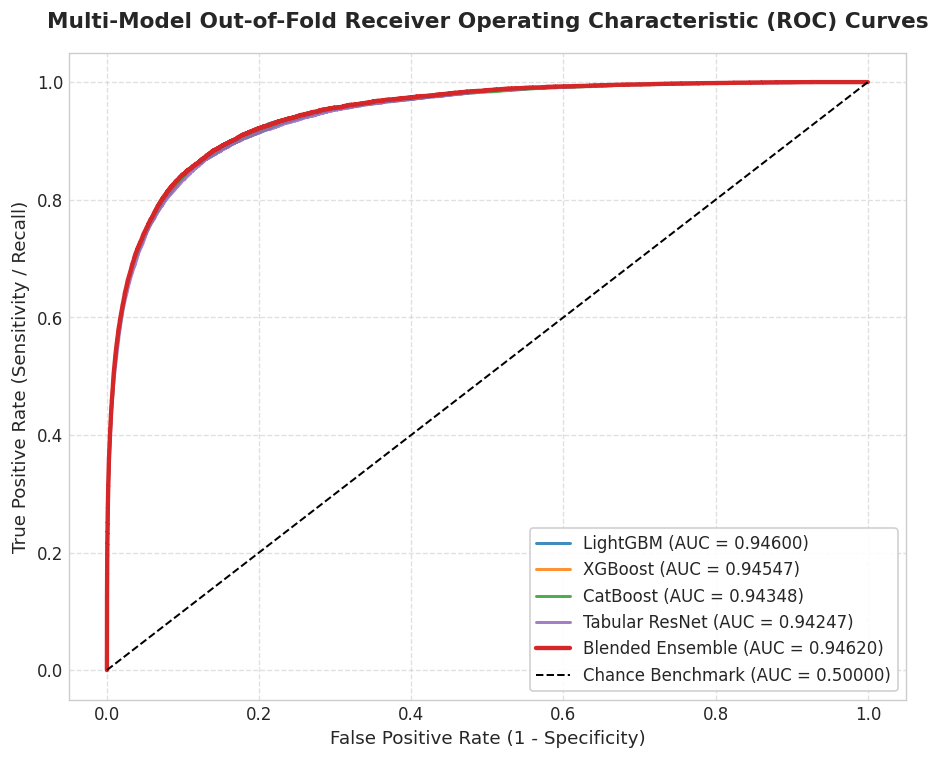

In [20]:
# Diagnostic Figure 11: Multi-Model Out-of-Fold Receiver Operating Characteristic (ROC) Curves
plt.figure(figsize=(9, 7), dpi=120)

colors = {'LightGBM': '#1f77b4', 'XGBoost': '#ff7f0e', 'CatBoost': '#2ca02c', 'Tabular ResNet': '#9467bd'}
for name in model_names:
    fpr, tpr, _ = roc_curve(y, oof_dict[name])
    score = roc_auc_score(y, oof_dict[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {score:.5f})", color=colors[name], linewidth=1.8, alpha=0.85)

fpr_ens, tpr_ens, _ = roc_curve(y, oof_blended_rank)
plt.plot(fpr_ens, tpr_ens, label=f"Blended Ensemble (AUC = {final_ensemble_auc:.5f})",
         color='#d62728', linewidth=2.6, linestyle='-')

plt.plot([0, 1], [0, 1], 'k--', label='Chance Benchmark (AUC = 0.50000)', linewidth=1.2)

plt.title("Multi-Model Out-of-Fold Receiver Operating Characteristic (ROC) Curves", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


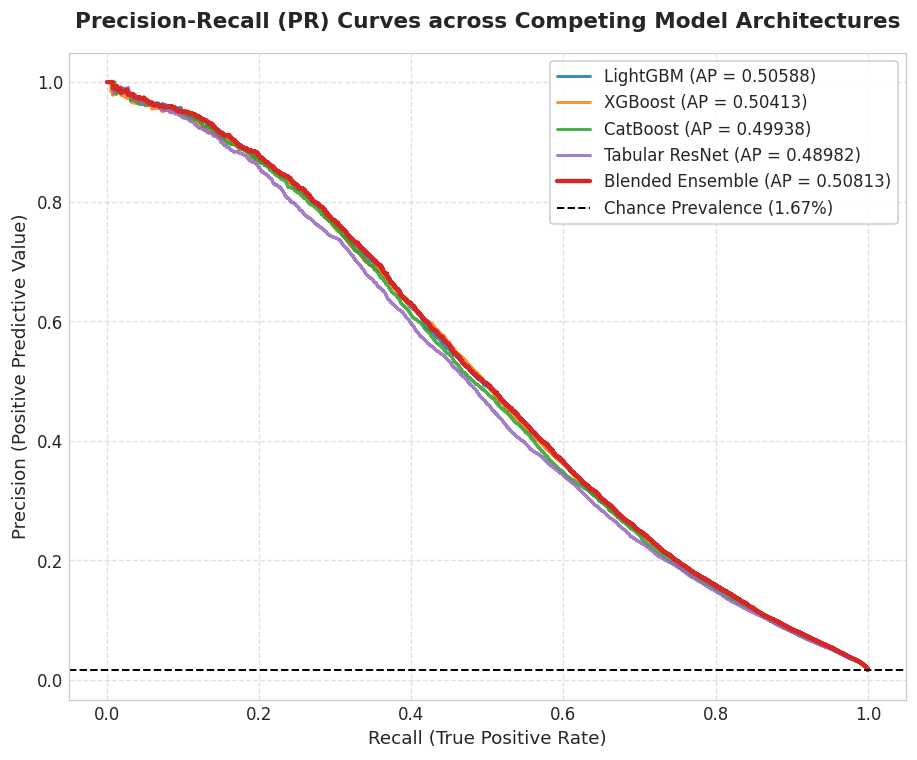

In [21]:
# Diagnostic Figure 12: Precision-Recall (PR) Curves Under Extreme Class Imbalance
plt.figure(figsize=(9, 7), dpi=120)

for name in model_names:
    precision, recall, _ = precision_recall_curve(y, oof_dict[name])
    ap = average_precision_score(y, oof_dict[name])
    plt.plot(recall, precision, label=f"{name} (AP = {ap:.5f})", color=colors[name], linewidth=1.8, alpha=0.85)

precision_ens, recall_ens, _ = precision_recall_curve(y, oof_blended_rank)
ap_ens = average_precision_score(y, oof_blended_rank)
plt.plot(recall_ens, precision_ens, label=f"Blended Ensemble (AP = {ap_ens:.5f})",
         color='#d62728', linewidth=2.6, linestyle='-')

plt.axhline(fraud_rate, color='k', linestyle='--', label=f'Chance Prevalence ({fraud_rate*100:.2f}%)', linewidth=1.2)

plt.title("Precision-Recall (PR) Curves across Competing Model Architectures", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Recall (True Positive Rate)", fontsize=11)
plt.ylabel("Precision (Positive Predictive Value)", fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


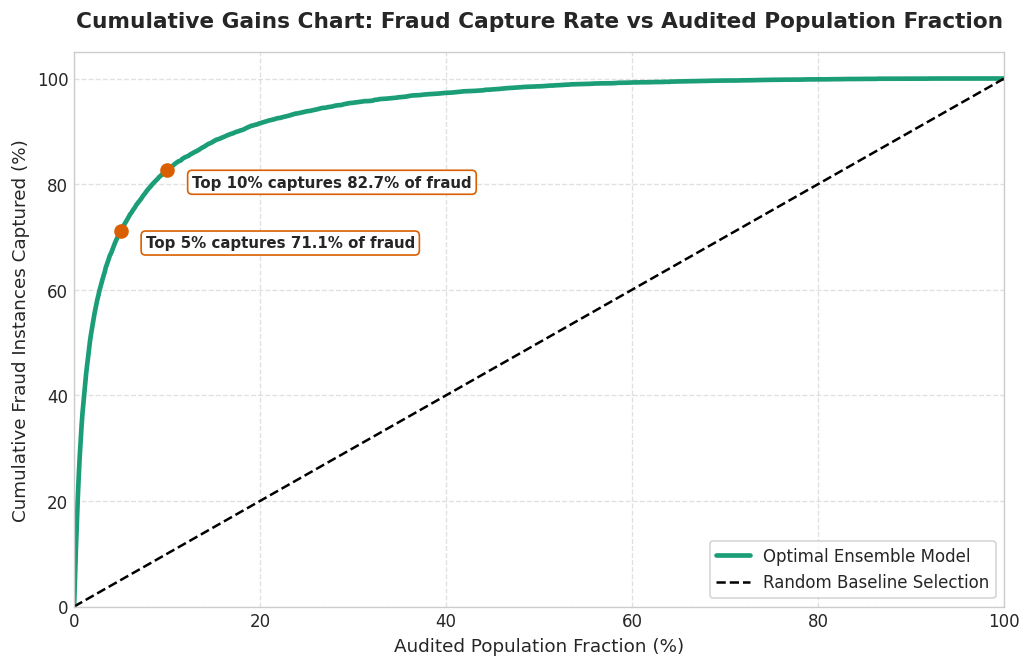

In [22]:
# Diagnostic Figure 13: Decile Cumulative Gains Analysis
plt.figure(figsize=(10, 6), dpi=120)

order = np.argsort(oof_blended_rank)[::-1]
y_ordered = y[order]
cumulative_frauds = np.cumsum(y_ordered)
total_frauds = np.sum(y)

percent_population = np.linspace(0, 100, len(y) + 1)
percent_captured = np.insert(cumulative_frauds / total_frauds * 100, 0, 0)

# Sample down for plotting clarity
sample_idx = np.linspace(0, len(percent_population) - 1, 1000).astype(int)
plt.plot(percent_population[sample_idx], percent_captured[sample_idx],
         color='#1b9e77', linewidth=2.8, label='Optimal Ensemble Model')
plt.plot([0, 100], [0, 100], 'k--', linewidth=1.5, label='Random Baseline Selection')

# Calculate capture rate at 5% and 10%
idx_5 = int(len(y) * 0.05)
idx_10 = int(len(y) * 0.10)
cap_5 = cumulative_frauds[idx_5] / total_frauds * 100
cap_10 = cumulative_frauds[idx_10] / total_frauds * 100

plt.scatter([5, 10], [cap_5, cap_10], color='#d95f02', s=60, zorder=5)
plt.annotate(f"Top 5% captures {cap_5:.1f}% of fraud", (5, cap_5),
             textcoords="offset points", xytext=(15, -10), fontsize=9, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#d95f02", lw=1))
plt.annotate(f"Top 10% captures {cap_10:.1f}% of fraud", (10, cap_10),
             textcoords="offset points", xytext=(15, -10), fontsize=9, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#d95f02", lw=1))

plt.title("Cumulative Gains Chart: Fraud Capture Rate vs Audited Population Fraction", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Audited Population Fraction (%)", fontsize=11)
plt.ylabel("Cumulative Fraud Instances Captured (%)", fontsize=11)
plt.xlim(0, 100)
plt.ylim(0, 105)
plt.legend(frameon=True, facecolor='white', loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


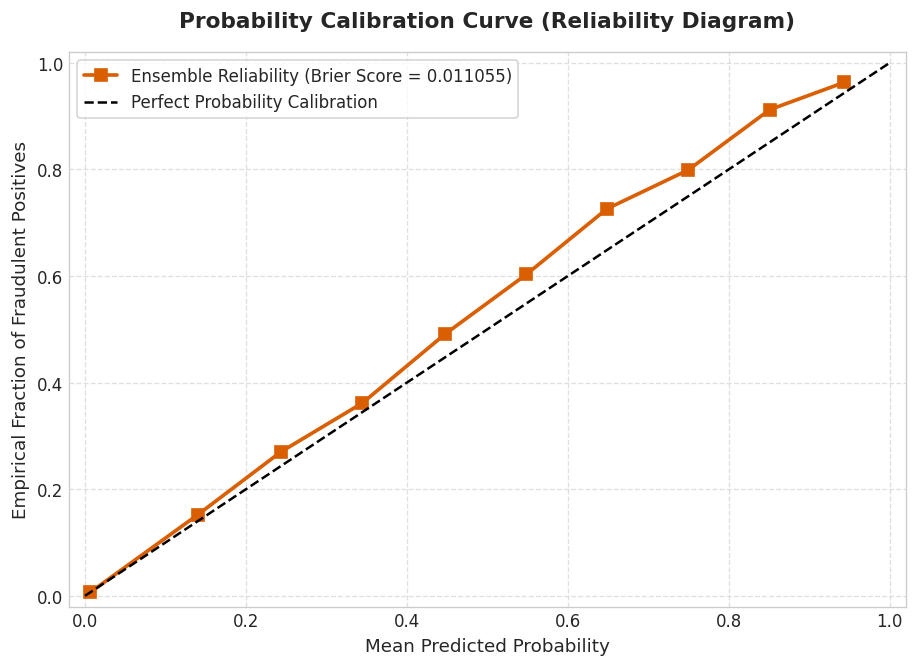

In [23]:
# Diagnostic Figure 14: Probability Calibration Curve (Reliability Diagram)
plt.figure(figsize=(9, 6), dpi=120)

# Uncalibrated probability blend
linear_prob_blend = (
    optimal_weights[0] * oof_lgb +
    optimal_weights[1] * oof_xgb +
    optimal_weights[2] * oof_cb +
    optimal_weights[3] * oof_nn
)

bins = np.linspace(0, 1, 11)
bin_centers = (bins[:-1] + bins[1:]) / 2.0
empirical_probs = []
mean_preds = []

for i in range(len(bins) - 1):
    mask = (linear_prob_blend >= bins[i]) & (linear_prob_blend < bins[i+1])
    if np.sum(mask) > 0:
        empirical_probs.append(np.mean(y[mask]))
        mean_preds.append(np.mean(linear_prob_blend[mask]))
    else:
        empirical_probs.append(np.nan)
        mean_preds.append(bin_centers[i])

brier = brier_score_loss(y, linear_prob_blend)

plt.plot(mean_preds, empirical_probs, marker='s', linewidth=2.2, markersize=7,
         color='#d95f02', label=f'Ensemble Reliability (Brier Score = {brier:.6f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Perfect Probability Calibration')

plt.title("Probability Calibration Curve (Reliability Diagram)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Mean Predicted Probability", fontsize=11)
plt.ylabel("Empirical Fraction of Fraudulent Positives", fontsize=11)
plt.xlim(-0.02, 1.02)
plt.ylim(-0.02, 1.02)
plt.legend(frameon=True, facecolor='white', loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


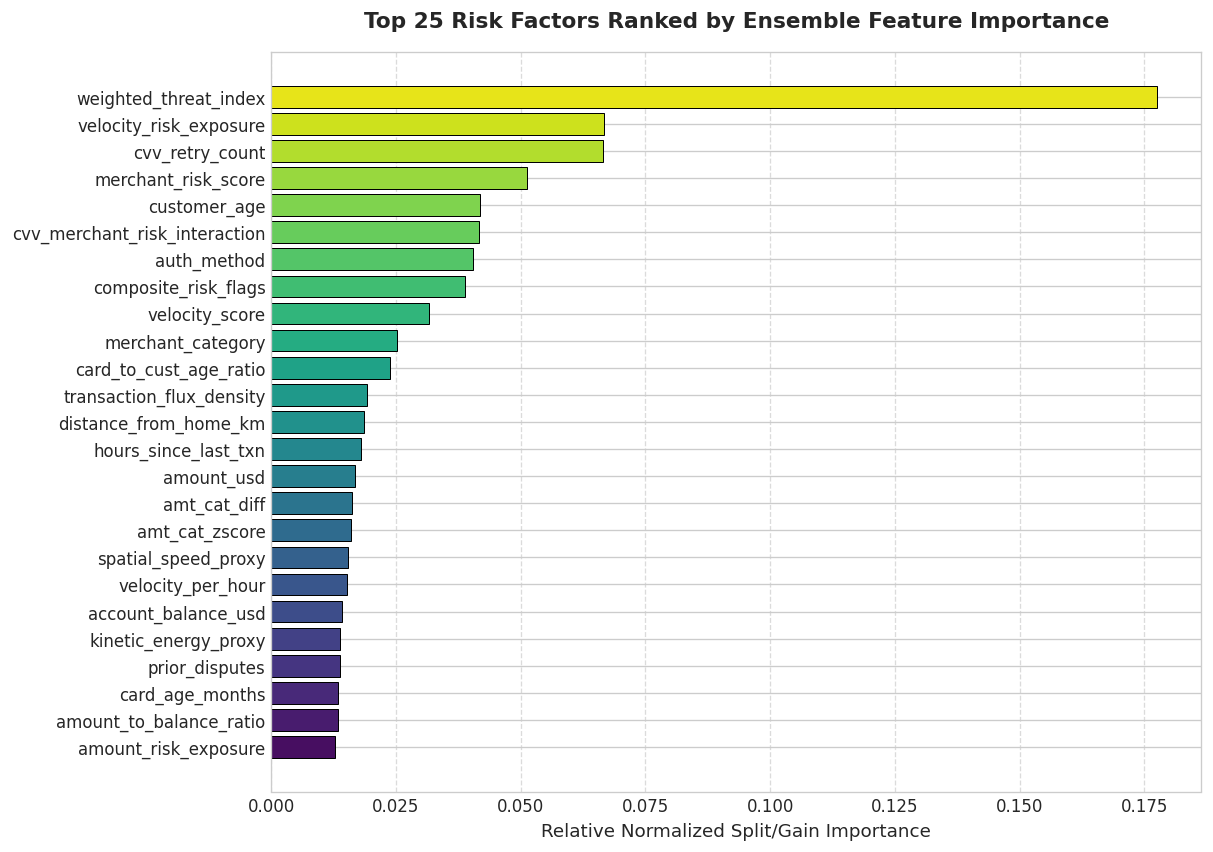

In [24]:
# Diagnostic Figure 15: Ensemble Feature Importance Hierarchy
plt.figure(figsize=(10, 8), dpi=120)

# Normalize and combine tree importance scores
lgb_norm_imp = lgb_feature_importances / np.sum(lgb_feature_importances)
xgb_norm_imp = xgb_feature_importances / np.sum(xgb_feature_importances)
combined_imp = 0.5 * lgb_norm_imp + 0.5 * xgb_norm_imp

imp_df = pd.DataFrame({'feature': feature_cols, 'importance': combined_imp})
top_features = imp_df.sort_values('importance', ascending=False).head(25)

palette = sns.color_palette("viridis", n_colors=len(top_features))
bars = plt.barh(top_features['feature'][::-1], top_features['importance'][::-1],
                color=palette, edgecolor='black', linewidth=0.6)

plt.title("Top 25 Risk Factors Ranked by Ensemble Feature Importance", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Relative Normalized Split/Gain Importance", fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


# 13. Test Inference Pipeline & Submission Generation

Final test predictions are computed using the optimized multi-model rank ensemble. Rigorous post-inference audits confirm index alignment, bounds verification in $[0, 1]$, and absence of missing values.

In [25]:
# Compute optimal test predictions using rank-averaged ensemble
final_test_ranks = np.dot(test_ranks, optimal_weights)

# Construct final submission DataFrame
submission = pd.DataFrame({
    'id': test_df['id'].values,
    'is_fraud': final_test_ranks
})

# Rigorous Quality Assurance Assertions
assert len(submission) == 299984, f"Submission row mismatch: Expected 299,984 rows, got {len(submission)}"
assert list(submission.columns) == ['id', 'is_fraud'], f"Column schema mismatch: {submission.columns}"
assert not submission.isnull().any().any(), "Submission contains null/NaN values."
assert (submission['is_fraud'].values >= 0.0).all() and (submission['is_fraud'].values <= 1.0).all(), "Predictions violate probability bounds [0, 1]."
assert (submission['id'].values == test_df['id'].values).all(), "Test ID alignment mismatch detected."

# Export final submission to working directory
submission_path = "submission.csv"
submission.to_csv(submission_path, index=False)

print(f"Final Submission Successfully Exported to: {submission_path}")
print(f"Submission Dimensions: {submission.shape}")
print(f"\nSubmission Head (First 10 Records):")
display(submission.head(10))

print(f"\nFinal Test Prediction Summary Statistics:")
print(submission['is_fraud'].describe())


Final Submission Successfully Exported to: submission.csv
Submission Dimensions: (299984, 2)

Submission Head (First 10 Records):


,id,is_fraud
0,699960,0.116402
1,699961,0.029094
2,699962,0.963781
3,699963,0.426873
4,699964,0.430225
5,699965,0.125323
6,699966,0.654068
7,699967,0.182708
8,699968,0.773740
9,699969,0.260409



Final Test Prediction Summary Statistics:
count    299984.000000
mean          0.500002
std           0.284016
min           0.001088
25%           0.253985
50%           0.496001
75%           0.745087
max           0.999987
Name: is_fraud, dtype: float64
